In [1]:
#Comienzo importando las librerías que necesitaré para el análisis y las visualziaciones.

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
#Creación de los dataframes a partir de los 3 archivos .csv.

visits = pd.read_csv('/datasets/visits_log_us.csv')
orders = pd.read_csv('/datasets/orders_log_us.csv')
costs = pd.read_csv('/datasets/costs_us.csv')

In [3]:
# Inicio explorando los datos de cada dataset.

visits.info()
print(visits.head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 359400 entries, 0 to 359399
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   Device     359400 non-null  object
 1   End Ts     359400 non-null  object
 2   Source Id  359400 non-null  int64 
 3   Start Ts   359400 non-null  object
 4   Uid        359400 non-null  uint64
dtypes: int64(1), object(3), uint64(1)
memory usage: 13.7+ MB
    Device               End Ts  Source Id             Start Ts  \
0    touch  2017-12-20 17:38:00          4  2017-12-20 17:20:00   
1  desktop  2018-02-19 17:21:00          2  2018-02-19 16:53:00   
2    touch  2017-07-01 01:54:00          5  2017-07-01 01:54:00   
3  desktop  2018-05-20 11:23:00          9  2018-05-20 10:59:00   
4  desktop  2017-12-27 14:06:00          3  2017-12-27 14:06:00   
5  desktop  2017-09-03 21:36:00          5  2017-09-03 21:35:00   
6  desktop  2018-01-30 12:09:00          1  2018-01-30 11:13:00   
7    touch  

In [4]:
orders.info()
print(orders.head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50415 entries, 0 to 50414
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Buy Ts   50415 non-null  object 
 1   Revenue  50415 non-null  float64
 2   Uid      50415 non-null  uint64 
dtypes: float64(1), object(1), uint64(1)
memory usage: 1.2+ MB
                Buy Ts  Revenue                   Uid
0  2017-06-01 00:10:00    17.00  10329302124590727494
1  2017-06-01 00:25:00     0.55  11627257723692907447
2  2017-06-01 00:27:00     0.37  17903680561304213844
3  2017-06-01 00:29:00     0.55  16109239769442553005
4  2017-06-01 07:58:00     0.37  14200605875248379450
5  2017-06-01 08:43:00     0.18  10402394430196413321
6  2017-06-01 08:54:00     1.83  12464626743129688638
7  2017-06-01 09:22:00     1.22   3644482766749211722
8  2017-06-01 09:22:00     3.30  17542070709969841479
9  2017-06-01 09:23:00     0.37   1074355127080856382


In [5]:
costs.info()
print(costs.head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2542 entries, 0 to 2541
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   source_id  2542 non-null   int64  
 1   dt         2542 non-null   object 
 2   costs      2542 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 59.7+ KB
   source_id          dt  costs
0          1  2017-06-01  75.20
1          1  2017-06-02  62.25
2          1  2017-06-03  36.53
3          1  2017-06-04  55.00
4          1  2017-06-05  57.08
5          1  2017-06-06  40.39
6          1  2017-06-07  40.59
7          1  2017-06-08  56.63
8          1  2017-06-09  40.16
9          1  2017-06-10  43.24


#### Notas: 
- Las columnas de tiempo de las tres tablas son "objects", por lo que será necesario transformarlas a datetime.
- También voy a renombrar los nombres de las columnas de orders y de visits para mantener el formato como en costs.

In [6]:
visits.columns = ['device','end_ts','source_id','start_ts','uid']
visits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 359400 entries, 0 to 359399
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   device     359400 non-null  object
 1   end_ts     359400 non-null  object
 2   source_id  359400 non-null  int64 
 3   start_ts   359400 non-null  object
 4   uid        359400 non-null  uint64
dtypes: int64(1), object(3), uint64(1)
memory usage: 13.7+ MB


In [7]:
orders.columns = ['buy_ts','revenue','uid']
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50415 entries, 0 to 50414
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   buy_ts   50415 non-null  object 
 1   revenue  50415 non-null  float64
 2   uid      50415 non-null  uint64 
dtypes: float64(1), object(1), uint64(1)
memory usage: 1.2+ MB


In [8]:
# Modifico los tipos de datos de las columnas de timestamps de cada dataset.

visits['start_ts'] = pd.to_datetime(visits['start_ts'])
visits['end_ts'] = pd.to_datetime(visits['end_ts'])
orders['buy_ts'] = pd.to_datetime(orders['buy_ts'])
costs['dt'] = pd.to_datetime(costs['dt'])

In [9]:
# Vuelvo a validar para verificar que los tiempos tengan el formato correcto.
visits.info()
orders.info()
costs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 359400 entries, 0 to 359399
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   device     359400 non-null  object        
 1   end_ts     359400 non-null  datetime64[ns]
 2   source_id  359400 non-null  int64         
 3   start_ts   359400 non-null  datetime64[ns]
 4   uid        359400 non-null  uint64        
dtypes: datetime64[ns](2), int64(1), object(1), uint64(1)
memory usage: 13.7+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50415 entries, 0 to 50414
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   buy_ts   50415 non-null  datetime64[ns]
 1   revenue  50415 non-null  float64       
 2   uid      50415 non-null  uint64        
dtypes: datetime64[ns](1), float64(1), uint64(1)
memory usage: 1.2 MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2542 entries, 0 to 2

In [10]:
# Reviso si hay duplicados.

duplicados_visits = visits.duplicated().sum()
duplicados_orders = orders.duplicated().sum()
duplicados_costs = costs.duplicated().sum()

print(f'Duplicados en Visits: {duplicados_visits}' )
print(f'Duplicados en Orders: {duplicados_orders}' )
print(f'Duplicados en Costs: {duplicados_costs}' )

print('------------------')

# Reviso si hay nulls.

nulls_visits = visits.isna().sum()
nulls_orders = orders.isna().sum()
nulls_costs = costs.isna().sum()

print(f'Nulls en Visits: {nulls_visits}' )
print(f'Nulls en Orders: {nulls_orders}' )
print(f'Nulls en Costs: {nulls_costs}' )


Duplicados en Visits: 0
Duplicados en Orders: 0
Duplicados en Costs: 0
------------------
Nulls en Visits: device       0
end_ts       0
source_id    0
start_ts     0
uid          0
dtype: int64
Nulls en Orders: buy_ts     0
revenue    0
uid        0
dtype: int64
Nulls en Costs: source_id    0
dt           0
costs        0
dtype: int64


#### Inicio preparación de datos para responder a la preguntas:
- ¿Cuántas personas lo usan cada día, semana y mes?
- ¿Cuántas sesiones hay por día? (Un usuario puede tener más de una sesión).
- ¿Cuál es la duración de cada sesión?
- ¿Con qué frecuencia los usuarios regresan?

In [11]:
# Creo las columnas de periodos de tiempo para el análisis de usuarios por día/semana/mes.

visits['visit_date'] = visits['start_ts'].dt.date
visits['visit_week'] = visits['start_ts'].dt.isocalendar().week
visits['visit_month'] = visits['start_ts'].dt.month
visits['visit_year'] = visits['start_ts'].dt.year

In [12]:
# Calculo el dau, wau y mau.

dau_total = visits.groupby('visit_date').agg({'uid':'nunique'}).mean()
wau_total = visits.groupby(['visit_year', 'visit_week']).agg({'uid':'nunique'}).mean()
mau_total = visits.groupby(['visit_year', 'visit_month']).agg({'uid':'nunique'}).mean()

print('Usuarios por día, semana y mes: ')
print(f'DAU: {int(dau_total)}')
print(f'WAU: {int(wau_total)}')
print(f'MAU: {int(mau_total)}')

Usuarios por día, semana y mes: 
DAU: 907
WAU: 5716
MAU: 23228


In [13]:
# Calculo los factores de adherencia que me indican los días en los que hubo usuarios activos en el mes y la semana.

sticky_mau = (dau_total / mau_total) * 100
sticky_wau = (dau_total / wau_total) * 100

print(sticky_wau)
print(sticky_mau)

uid    15.884409
dtype: float64
uid    3.90897
dtype: float64


## Sesiones de usuario por dia

In [14]:
# Creo df de sesiones por día agrupando el df original de visits por visit date, contando los user ids y promediando ese conteo por día.

sessions_per_day = visits.groupby('visit_date')['uid'].count().mean()

In [15]:
print(f'En promedio, hay {round(sessions_per_day, 2)} sesiones de usuario al día.')

En promedio, hay 987.36 sesiones de usuario al día.


In [16]:
visits['session_duration_sec'] = (visits['end_ts'] - visits['start_ts']).dt.total_seconds()
print(f"La duración promedio de cada sesión es {round(visits['session_duration_sec'].mean(),2)} segundos")

La duración promedio de cada sesión es 643.03 segundos


In [17]:
# Verifico si hay valores negativos en la duración de sesión.

print(visits[visits['session_duration_sec']<0])

         device              end_ts  source_id            start_ts  \
4181    desktop 2018-03-25 03:18:00          3 2018-03-25 03:50:00   
177972  desktop 2018-03-25 03:09:00          9 2018-03-25 03:55:00   

                         uid  visit_date  visit_week  visit_month  visit_year  \
4181    13092152539246794986  2018-03-25          12            3        2018   
177972   4621202742905035453  2018-03-25          12            3        2018   

        session_duration_sec  
4181                 -1920.0  
177972               -2760.0  


#### Notas: 
- Veo que hay 2 filas con una duración negativa, lo cuál es incorrecto.
- Dado que son 2 errores en 359,400 registros, decido excluir esos dos registros.
- Adicionalmente, noté que los errores son del mismo dia, y durante la misma hora (3 am) y en Desktop.
- Entonces puede ser que haya habido un error en el sistema para el registro de estos datos durante ese rato. Es algo que llevaría con el equipo de ingeniería de la empresa.

In [18]:
# Le asigno a visits el filtro lógico para excluir los registros cuando el valor de duración es menor a 0.

visits = visits[~(visits['session_duration_sec']<0)]

In [19]:
# Valido que la cantidad de registros bajó de 359,400 a 359,398, lo cual es justo lo que buscaba.

print(visits.info())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 359398 entries, 0 to 359399
Data columns (total 10 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   device                359398 non-null  object        
 1   end_ts                359398 non-null  datetime64[ns]
 2   source_id             359398 non-null  int64         
 3   start_ts              359398 non-null  datetime64[ns]
 4   uid                   359398 non-null  uint64        
 5   visit_date            359398 non-null  object        
 6   visit_week            359398 non-null  UInt32        
 7   visit_month           359398 non-null  int64         
 8   visit_year            359398 non-null  int64         
 9   session_duration_sec  359398 non-null  float64       
dtypes: UInt32(1), datetime64[ns](2), float64(1), int64(3), object(2), uint64(1)
memory usage: 29.1+ MB
None


In [20]:
# Creo el df de sesiones por usuario agrupando el df original de visits por visit_month y user id, con el valor de la cuenta de user ids.

sessions_per_user = visits.groupby(['visit_month', 'uid']).agg({'uid':'count'})
sessions_per_user.columns = ['total_sessions']
print(sessions_per_user)

                                  total_sessions
visit_month uid                                 
1           397399764396656                    1
            526778907996220                    1
            577434573913691                    1
            1807089377214406                   1
            2464366381792757                   2
...                                          ...
12          18445456946869452085               1
            18445883325006294312               1
            18445884613277162497               1
            18446424184725333426               1
            18446621818809592527               1

[278741 rows x 1 columns]


In [21]:
# Calculo la moda, minimo y máximo de las visitas por usuario al mes.

print(f"La moda de cantidad de visitas (frecuencia en la que visitan los usuarios) es de: {sessions_per_user['total_sessions'].mode().iloc[0]}.")
print(f"La cantidad mínima de visitas en el mes por usuario es: {sessions_per_user['total_sessions'].min()}.")
print(f"La cantidad máxima de visitas en el mes por usuario es: {sessions_per_user['total_sessions'].max()}.")

La moda de cantidad de visitas (frecuencia en la que visitan los usuarios) es de: 1.
La cantidad mínima de visitas en el mes por usuario es: 1.
La cantidad máxima de visitas en el mes por usuario es: 145.


#### Notas:
- El sticky_mau y la moda de visitas por usuario por mes coincide en 1, lo que nos dice que la mayoría de los usuarios solo utilizan una vez por mes la aplicación. O sea que la retención es muy baja.

<AxesSubplot:>

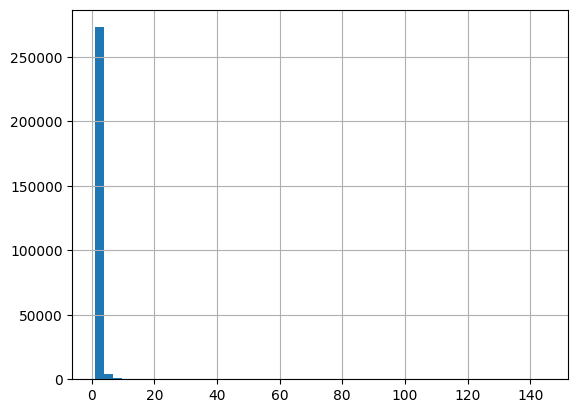

In [22]:
# Creo un histograma para comenzar a analizar visualmente los datos de sesiones por usuario.

sessions_per_user['total_sessions'].hist(bins=50)

#### Notas:
- Veo que casi el 100% de los registros parecen estar en 1 visita, y el eje X llega hasta 145, aunque no se ven bins, lo que indica que el valor máximo (y otros valores que peuda haber entre 3 y 145) no se repiten lo suficiente como para ser comparables con la moda.

(array([2.78199e+05, 3.75000e+02, 1.00000e+02, 2.80000e+01, 2.30000e+01,
        8.00000e+00, 0.00000e+00, 4.00000e+00, 2.00000e+00, 2.00000e+00]),
 array([  1. ,  15.4,  29.8,  44.2,  58.6,  73. ,  87.4, 101.8, 116.2,
        130.6, 145. ]),
 <BarContainer object of 10 artists>)

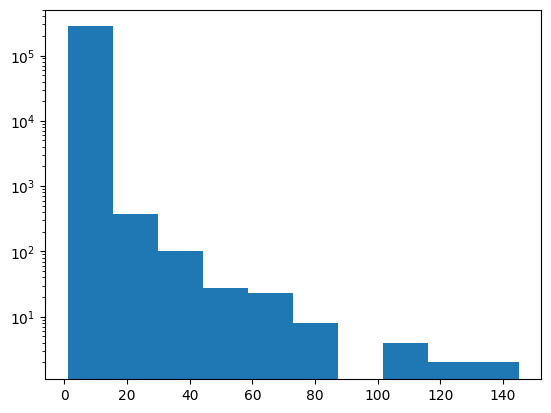

In [23]:
# Creo otro histrograma con escala logarítmica en el eje Y para poder visualizar mejor los buckets en los que hay muy pocos usuarios.

plt.hist(sessions_per_user['total_sessions'], log= True)

In [24]:
# No me gusta el array que arroja el histograma, porque no es facil interpretar "2.78199e+05" en números enteros, entonces, usaré esa información para crear una tabla legible.

# Primero guardo los arrays del resultado del histograma en variables.
frecuencias, bins, _ = plt.hist(sessions_per_user['total_sessions'], log = True)

# Agrego plt.close() para solo obtener la tabla y no volver a dibujar el histograma.
plt.close()

# Creo la tabla como un dataframe. 
# bin_min va desde el inicio hasta el último valor del array de bins, pero sin incluir ese último valor.
# bn_max va desde el valor numero 2, o posición 1 hasta el final).
# De ese modo, me sirve para crear rangos para los bins de la tabla.

tabla_hist = pd.DataFrame({
    'bin_min': bins[:-1],
    'bin_max': bins[1:],
    'registros': frecuencias.astype(int)
})

# Utilizo una lambda para crear los f-strings que muestren los rangos de cada bin.
tabla_hist['rango'] = tabla_hist.apply(lambda x: f"[{x.bin_min:.1f} - {x.bin_max:.1f})", axis=1)
tabla_hist['%'] = (tabla_hist['registros'] / tabla_hist['registros'].sum() * 100).round(3)

# Muestro la tabla con la cantidad de registros en cada rango.
tabla_hist[['rango', 'registros', '%']]

,rango,registros,%
0,[1.0 - 15.4),278199,99.806
1,[15.4 - 29.8),375,0.135
2,[29.8 - 44.2),100,0.036
3,[44.2 - 58.6),28,0.010
4,[58.6 - 73.0),23,0.008
5,[73.0 - 87.4),8,0.003
6,[87.4 - 101.8),0,0.000
7,[101.8 - 116.2),4,0.001
8,[116.2 - 130.6),2,0.001
9,[130.6 - 145.0),2,0.001


#### Conclusiones:
- Nuestro nivel de retención a lo largo del mes es muy baja: 99.8% de los usuarios que ingresan a la app en el mes no lo vuelven a hacer en el resto del mes.
- Necesitamos profundizar en por qué no la siguen usando y por qué hay usuarios que la utilizan más, tanto los que la usan de manera moderada (15 a 29 veces al mes), así como los que la usan mucho, para identificar si existen problemas técnicos, oportunidades de mejora en la UI, etc.

## Análisis de Ventas

In [25]:
# Creo el df de primeras visitas agrupando visits por user id, y asignando el timestamp minimo de inicio de sesion (inicio de la primera visita).

first_visits = visits.groupby('uid')['start_ts'].min()
first_visits.name = 'first_visit'
print(first_visits.head(5))


uid
11863502262781    2018-03-01 17:27:00
49537067089222    2018-02-06 15:55:00
297729379853735   2017-06-07 18:47:00
313578113262317   2017-09-18 22:49:00
325320750514679   2017-09-30 14:29:00
Name: first_visit, dtype: datetime64[ns]


In [26]:
print(orders.head(5))

               buy_ts  revenue                   uid
0 2017-06-01 00:10:00    17.00  10329302124590727494
1 2017-06-01 00:25:00     0.55  11627257723692907447
2 2017-06-01 00:27:00     0.37  17903680561304213844
3 2017-06-01 00:29:00     0.55  16109239769442553005
4 2017-06-01 07:58:00     0.37  14200605875248379450


In [27]:
# Creo el df de primeras ordenes agrupando por user id, con el timestamp minimo de compra (fecha y hora de primera compra).

first_orders = orders.groupby('uid')['buy_ts'].min()
first_orders.name = 'first_order'
print(first_orders.head(5))


uid
313578113262317    2018-01-03 21:51:00
1575281904278712   2017-06-03 10:13:00
2429014661409475   2017-10-11 18:33:00
2464366381792757   2018-01-28 15:54:00
2551852515556206   2017-11-24 10:14:00
Name: first_order, dtype: datetime64[ns]


In [28]:
# Combino orders con first_orders para tener acceso a las fechas de las primeras ordenes desde el df original de orders.

orders = orders.join(first_orders, on='uid')
print(orders.head(5))

# Combino orders con first_visits para tener acceso a las fechas de las primeras visitas desde el df de orders.
orders = orders.join(first_visits, on='uid')
print(orders.head(5))

               buy_ts  revenue                   uid         first_order
0 2017-06-01 00:10:00    17.00  10329302124590727494 2017-06-01 00:10:00
1 2017-06-01 00:25:00     0.55  11627257723692907447 2017-06-01 00:25:00
2 2017-06-01 00:27:00     0.37  17903680561304213844 2017-06-01 00:27:00
3 2017-06-01 00:29:00     0.55  16109239769442553005 2017-06-01 00:29:00
4 2017-06-01 07:58:00     0.37  14200605875248379450 2017-06-01 07:58:00
               buy_ts  revenue                   uid         first_order  \
0 2017-06-01 00:10:00    17.00  10329302124590727494 2017-06-01 00:10:00   
1 2017-06-01 00:25:00     0.55  11627257723692907447 2017-06-01 00:25:00   
2 2017-06-01 00:27:00     0.37  17903680561304213844 2017-06-01 00:27:00   
3 2017-06-01 00:29:00     0.55  16109239769442553005 2017-06-01 00:29:00   
4 2017-06-01 07:58:00     0.37  14200605875248379450 2017-06-01 07:58:00   

          first_visit  
0 2017-06-01 00:09:00  
1 2017-06-01 00:14:00  
2 2017-06-01 00:25:00  
3 2017-06

In [29]:
# Creo la columna de days_to_first_order, restandole a first_order la fecha de first_visit y asi obtener la cantidad de días que se demoró cada usuario en comprar desde su primera visita.

orders['days_to_first_order'] = (orders['first_order'] - orders['first_visit']).dt.days
print(orders.head(5))

               buy_ts  revenue                   uid         first_order  \
0 2017-06-01 00:10:00    17.00  10329302124590727494 2017-06-01 00:10:00   
1 2017-06-01 00:25:00     0.55  11627257723692907447 2017-06-01 00:25:00   
2 2017-06-01 00:27:00     0.37  17903680561304213844 2017-06-01 00:27:00   
3 2017-06-01 00:29:00     0.55  16109239769442553005 2017-06-01 00:29:00   
4 2017-06-01 07:58:00     0.37  14200605875248379450 2017-06-01 07:58:00   

          first_visit  days_to_first_order  
0 2017-06-01 00:09:00                    0  
1 2017-06-01 00:14:00                    0  
2 2017-06-01 00:25:00                    0  
3 2017-06-01 00:14:00                    0  
4 2017-06-01 07:31:00                    0  


In [30]:
# Verifico si existen valores negativos en la nueva columna de days_to_first_orders.

print(orders[orders['days_to_first_order']<0])

Empty DataFrame
Columns: [buy_ts, revenue, uid, first_order, first_visit, days_to_first_order]
Index: []


#### Notas:
- Dado que no hay valores negativos, podemos continuar con la seguridad de que no hay discrepancias en los datos en cuanto a las fechas de primera compra y primera visita.

In [31]:
# Creo la nueva columna de mes de primera visita.

orders['first_visit_month'] = orders['first_visit'].astype('datetime64[M]')
print(orders.head(5))

               buy_ts  revenue                   uid         first_order  \
0 2017-06-01 00:10:00    17.00  10329302124590727494 2017-06-01 00:10:00   
1 2017-06-01 00:25:00     0.55  11627257723692907447 2017-06-01 00:25:00   
2 2017-06-01 00:27:00     0.37  17903680561304213844 2017-06-01 00:27:00   
3 2017-06-01 00:29:00     0.55  16109239769442553005 2017-06-01 00:29:00   
4 2017-06-01 07:58:00     0.37  14200605875248379450 2017-06-01 07:58:00   

          first_visit  days_to_first_order first_visit_month  
0 2017-06-01 00:09:00                    0        2017-06-01  
1 2017-06-01 00:14:00                    0        2017-06-01  
2 2017-06-01 00:25:00                    0        2017-06-01  
3 2017-06-01 00:14:00                    0        2017-06-01  
4 2017-06-01 07:31:00                    0        2017-06-01  


In [32]:
# Creo una tabla pivote para mostrar la cuenta de user ids con el mes de primera visita como filas y los días que se demoraron en comprar en las columnas.

orders.pivot_table(
    index = 'first_visit_month',
    columns = 'days_to_first_order',
    values = 'uid',
    aggfunc = 'count',
)

days_to_first_order,0,1,2,3,4,5,6,7,8,9,...,346,347,348,349,352,354,355,357,362,363
first_visit_month,,,,,,,,,,,,,,,,,,,,,
2017-06-01,3364.0,364.0,32.0,61.0,177.0,65.0,35.0,14.0,170.0,15.0,...,4.0,5.0,1.0,6.0,3.0,1.0,3.0,4.0,1.0,1.0
2017-07-01,2020.0,73.0,55.0,27.0,30.0,29.0,24.0,16.0,18.0,7.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-08-01,1501.0,220.0,16.0,16.0,19.0,11.0,17.0,11.0,6.0,7.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-01,2647.0,97.0,51.0,51.0,41.0,44.0,45.0,34.0,22.0,25.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-10-01,4294.0,144.0,100.0,85.0,50.0,54.0,74.0,46.0,21.0,23.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-11-01,3872.0,197.0,191.0,117.0,47.0,57.0,169.0,33.0,29.0,39.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-12-01,3803.0,180.0,92.0,106.0,107.0,44.0,33.0,34.0,22.0,24.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-01-01,2854.0,115.0,64.0,57.0,66.0,33.0,30.0,25.0,26.0,19.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-02-01,2955.0,116.0,82.0,49.0,51.0,84.0,30.0,44.0,18.0,22.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:
print(orders['days_to_first_order'].describe())

count    50415.000000
mean        17.419677
std         46.352290
min          0.000000
25%          0.000000
50%          0.000000
75%          4.000000
max        363.000000
Name: days_to_first_order, dtype: float64


#### Notas:
- Veo que al final de la tabla hay columnas arriba de 300 días.
- Valido con un describe() y veo que efectivamente el máximo es 363 días.

In [34]:
# Creo un df agrupando los días que pasaron entre la primera visita y la compra, en los bins que habia definido previamente en el paso del histograma.

orders['order_cohort'] = pd.cut(orders['days_to_first_order'], bins=bins, right = True, include_lowest = True)

In [35]:
# Cuento los valores que caen en cada rango para identificar los rangos con mayor cantidad de usuarios que demoraron esos dias en comprar.

orders['order_cohort'].value_counts(sort=False)


(0.999, 15.4]     7180
(15.4, 29.8]      1721
(29.8, 44.2]      1193
(44.2, 58.6]       824
(58.6, 73.0]       730
(73.0, 87.4]       547
(87.4, 101.8]      674
(101.8, 116.2]     546
(116.2, 130.6]     493
(130.6, 145.0]     339
Name: order_cohort, dtype: int64

In [36]:
# Me di cuenta de que primero realicé la tabla pivote con base en el 100% de los registros de ordenes, pero más adelante realizo un filtro para solo mostrar las primeras ordenes vs primeras visitas.

orders.pivot_table(
    index = 'first_visit_month',
    columns = 'order_cohort',
    values = 'uid',
    aggfunc = 'count',
)

order_cohort,"(0.999, 15.4]","(15.4, 29.8]","(29.8, 44.2]","(44.2, 58.6]","(58.6, 73.0]","(73.0, 87.4]","(87.4, 101.8]","(101.8, 116.2]","(116.2, 130.6]","(130.6, 145.0]"
first_visit_month,,,,,,,,,,
2017-06-01,1179,220,171,70,86,80,186,167,120,60
2017-07-01,352,111,84,109,97,82,71,65,83,79
2017-08-01,368,105,74,57,69,43,72,49,46,21
2017-09-01,649,180,133,98,114,88,68,49,29,43
2017-10-01,715,265,198,146,94,58,94,58,76,49
2017-11-01,1053,261,161,102,82,65,75,74,69,41
2017-12-01,739,150,118,88,70,67,47,40,30,34
2018-01-01,506,150,91,84,49,27,26,27,38,12
2018-02-01,570,114,71,36,39,27,35,17,2,0


In [37]:
# Creo df de first_orders basado en orders pero filtrando unicamente las filas en las que el timestamp de orden coincida con el timestamp de la primera orden y así dejar solo primeras órdenes.

first_orders = orders[orders['first_order'] == orders['buy_ts']]
print(first_orders.head(5))

               buy_ts  revenue                   uid         first_order  \
0 2017-06-01 00:10:00    17.00  10329302124590727494 2017-06-01 00:10:00   
1 2017-06-01 00:25:00     0.55  11627257723692907447 2017-06-01 00:25:00   
2 2017-06-01 00:27:00     0.37  17903680561304213844 2017-06-01 00:27:00   
3 2017-06-01 00:29:00     0.55  16109239769442553005 2017-06-01 00:29:00   
4 2017-06-01 07:58:00     0.37  14200605875248379450 2017-06-01 07:58:00   

          first_visit  days_to_first_order first_visit_month order_cohort  
0 2017-06-01 00:09:00                    0        2017-06-01          NaN  
1 2017-06-01 00:14:00                    0        2017-06-01          NaN  
2 2017-06-01 00:25:00                    0        2017-06-01          NaN  
3 2017-06-01 00:14:00                    0        2017-06-01          NaN  
4 2017-06-01 07:31:00                    0        2017-06-01          NaN  


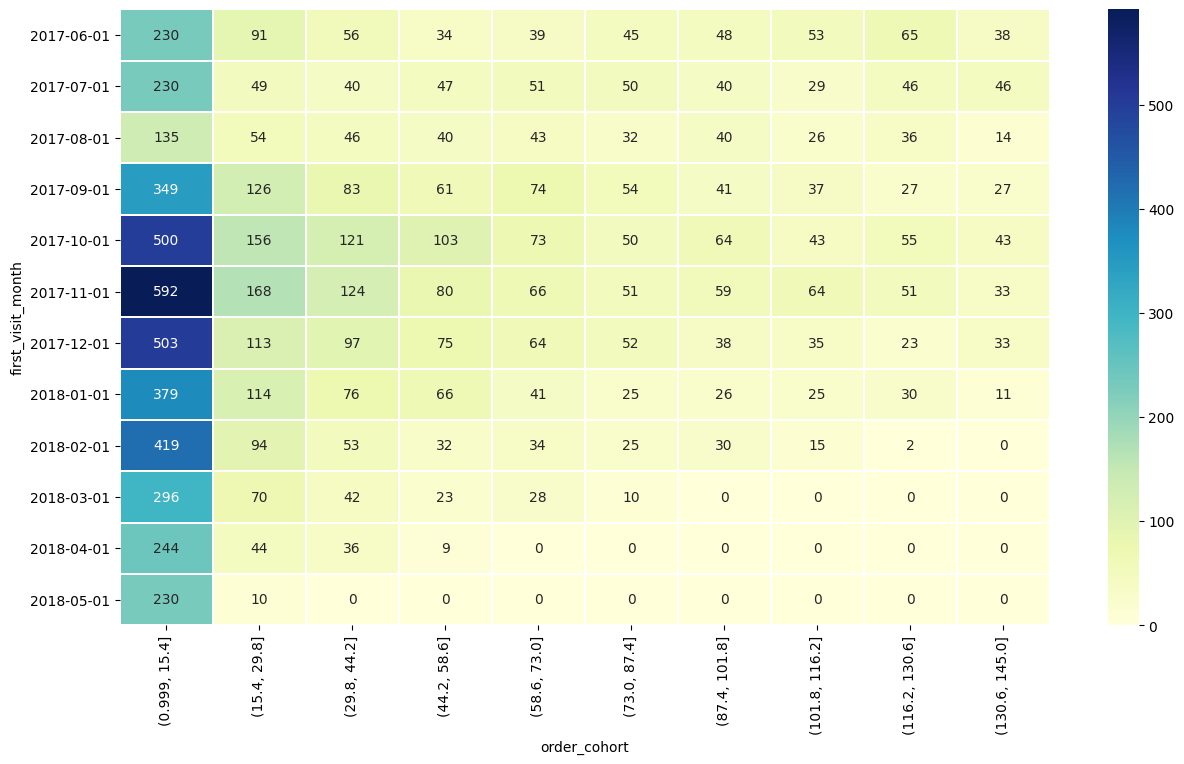

In [38]:
# Creo la pivote con base en solo las primeras ordenes y aplico un heatmap para mejor visualización de los datos.

first_orders_pivot = first_orders.pivot_table(
    index = 'first_visit_month',
    columns = 'order_cohort',
    values = 'uid',
    aggfunc = 'count',
)
first_orders_pivot.index = first_orders_pivot.index.strftime('%Y-%m-%d')

plt.figure(figsize=(15,8))
ax = sns.heatmap(
    first_orders_pivot,
    annot=True,
    fmt= "d",
    cmap="YlGnBu",
    linewidth= 0.5
)

#### Notas:
- El rango de 1 a 15 días sigue siendo el más recurrente, indicando que la mayoría de las ordenes ocurren en las primeras visitas.
- Esto podría sugerir que la mayoría de los visitantes entran a la app con un objetivo muy puntual en mente: comprar boletos para un evento de su interés en particular.
- No se meten tantas veces, sino que la mayoría compra el mismo día que ingresa, o dentro de los primeros 15 días.

In [39]:
print(orders.head(5))

               buy_ts  revenue                   uid         first_order  \
0 2017-06-01 00:10:00    17.00  10329302124590727494 2017-06-01 00:10:00   
1 2017-06-01 00:25:00     0.55  11627257723692907447 2017-06-01 00:25:00   
2 2017-06-01 00:27:00     0.37  17903680561304213844 2017-06-01 00:27:00   
3 2017-06-01 00:29:00     0.55  16109239769442553005 2017-06-01 00:29:00   
4 2017-06-01 07:58:00     0.37  14200605875248379450 2017-06-01 07:58:00   

          first_visit  days_to_first_order first_visit_month order_cohort  
0 2017-06-01 00:09:00                    0        2017-06-01          NaN  
1 2017-06-01 00:14:00                    0        2017-06-01          NaN  
2 2017-06-01 00:25:00                    0        2017-06-01          NaN  
3 2017-06-01 00:14:00                    0        2017-06-01          NaN  
4 2017-06-01 07:31:00                    0        2017-06-01          NaN  


In [40]:
# Preparo las columnas de fecha, semana, mes y año en el df de ordenes.

orders['order_date'] = orders['buy_ts'].dt.date
orders['order_week'] = orders['buy_ts'].dt.isocalendar().week
orders['order_month'] = orders['buy_ts'].dt.month
orders['order_year'] = orders['buy_ts'].dt.year

In [41]:
# Creo df para agrupar los user ids por año y mes de compra y así obtener la cuenta de ordenes por mes de cada año.

orders_by_month = orders.groupby(['order_year', 'order_month'])['uid'].count()
print(orders_by_month)

order_year  order_month
2017        6              2354
            7              2363
            8              1807
            9              3387
            10             5679
            11             5659
            12             6218
2018        1              4721
            2              5281
            3              5326
            4              3273
            5              4346
            6                 1
Name: uid, dtype: int64


In [42]:
# Creo una columna de año con mes para poder utilizarla en mi gráfica y no tener dos columnas para index separadas (año y mes).

orders_by_month = orders_by_month.reset_index()
orders_by_month['year_and_month'] = pd.to_datetime(orders_by_month['order_year'].astype(str) + '-' + orders_by_month['order_month'].astype(str) ).dt.to_period('M')

print(orders_by_month.sample(10))

    order_year  order_month   uid year_and_month
4         2017           10  5679        2017-10
6         2017           12  6218        2017-12
9         2018            3  5326        2018-03
3         2017            9  3387        2017-09
0         2017            6  2354        2017-06
5         2017           11  5659        2017-11
2         2017            8  1807        2017-08
1         2017            7  2363        2017-07
10        2018            4  3273        2018-04
8         2018            2  5281        2018-02


In [43]:
orders_by_month.columns

Index(['order_year', 'order_month', 'uid', 'year_and_month'], dtype='object')

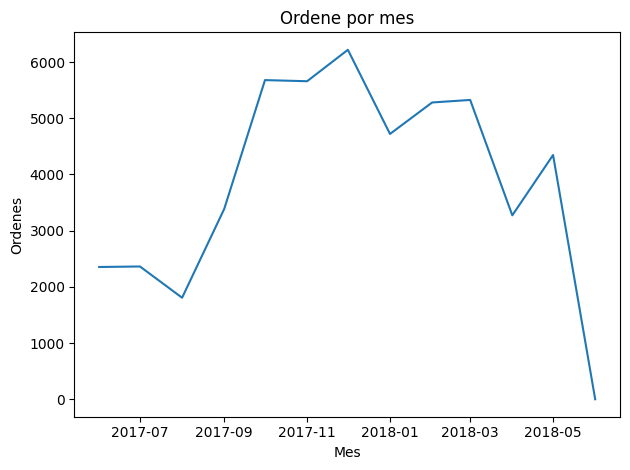

In [44]:
# Creo una gráfica de línea para visualizar la cantidad de ordenes mes a mes.

sns.lineplot(x= orders_by_month['year_and_month'].dt.to_timestamp(), y= orders_by_month['uid'], data=orders_by_month)
plt.title('Ordene por mes')
plt.xlabel('Mes')
plt.ylabel('Ordenes')
plt.tight_layout()

plt.show()

In [45]:
# Creo un df para ver el revenue por mes, a partir de ordenar el df orders por año y mes de orden, promediando el revenue.

revenue_by_month = orders.groupby(['order_year', 'order_month'])['revenue'].mean()
print(revenue_by_month.head(12))

revenue_by_month = revenue_by_month.reset_index()

revenue_by_month['year_and_month'] = pd.to_datetime(revenue_by_month['order_year'].astype(str) + '-' + revenue_by_month['order_month'].astype(str) ).dt.to_period('M')

year = revenue_by_month['order_year'].astype(int).astype(str)
month = revenue_by_month['order_month'].astype(int).astype(str).str.zfill(2)

# Creo una columna 'year_month' tipo period para poder utilizarla en las siguientes visualziaciones.
revenue_by_month['year_and_month'] = pd.to_datetime(
    year + '-' + month, format='%Y-%m'
).dt.to_period('M')

# Ordeno el df para ver los meses en orden.
revenue_by_month = revenue_by_month.sort_values('year_and_month')

order_year  order_month
2017        6              4.060106
            7              5.306589
            8              4.847139
            9              5.416448
            10             4.928280
            11             4.783518
            12             5.852139
2018        1              4.112927
            2              4.840095
            3              5.413930
            4              5.150645
            5              4.771279
Name: revenue, dtype: float64


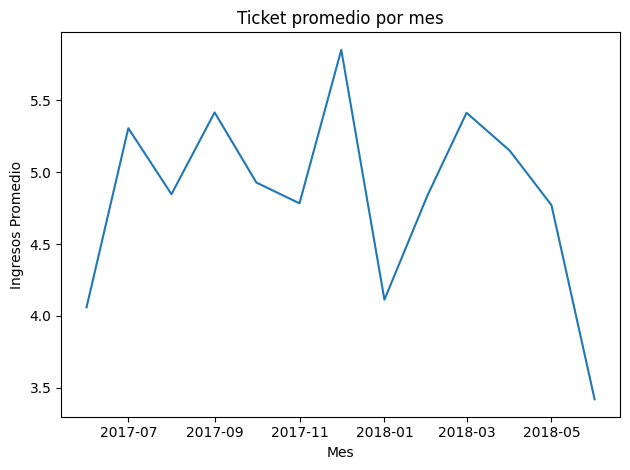

In [46]:
# Creo una gráfica de línea para visualizar el promedio de compra por mes.

sns.lineplot(x= revenue_by_month['year_and_month'].dt.to_timestamp(), y= revenue_by_month['revenue'], data=revenue_by_month)

plt.title('Ticket promedio por mes')
plt.xlabel('Mes')
plt.ylabel('Ingresos Promedio')
plt.tight_layout()

plt.show()


## LTV

In [47]:
# Reviso las columnas y datos que tengo en df de Orders para ver si me falta alguna de las columnas que necesito para calcular el LTV.

print(orders.head(10))
orders.columns

               buy_ts  revenue                   uid         first_order  \
0 2017-06-01 00:10:00    17.00  10329302124590727494 2017-06-01 00:10:00   
1 2017-06-01 00:25:00     0.55  11627257723692907447 2017-06-01 00:25:00   
2 2017-06-01 00:27:00     0.37  17903680561304213844 2017-06-01 00:27:00   
3 2017-06-01 00:29:00     0.55  16109239769442553005 2017-06-01 00:29:00   
4 2017-06-01 07:58:00     0.37  14200605875248379450 2017-06-01 07:58:00   
5 2017-06-01 08:43:00     0.18  10402394430196413321 2017-06-01 08:43:00   
6 2017-06-01 08:54:00     1.83  12464626743129688638 2017-06-01 08:54:00   
7 2017-06-01 09:22:00     1.22   3644482766749211722 2017-06-01 09:22:00   
8 2017-06-01 09:22:00     3.30  17542070709969841479 2017-06-01 09:22:00   
9 2017-06-01 09:23:00     0.37   1074355127080856382 2017-06-01 09:23:00   

          first_visit  days_to_first_order first_visit_month order_cohort  \
0 2017-06-01 00:09:00                    0        2017-06-01          NaN   
1 2017-06

Index(['buy_ts', 'revenue', 'uid', 'first_order', 'first_visit',
       'days_to_first_order', 'first_visit_month', 'order_cohort',
       'order_date', 'order_week', 'order_month', 'order_year'],
      dtype='object')

Notas: me hace falta una columna de 'first_order_month' para poder agrupar orders y calcular el LTV.

In [48]:
# Creo las columnas de first_order_month y order_period como periodos para utilizarlos como intervalos de tiempo.
# Calculo el cohort_age correspondiente a cada compra por usuario.

orders['first_order_month'] = orders['first_order'].dt.to_period('M')
orders['order_period'] = orders['buy_ts'].dt.to_period('M')
orders['cohort_age'] = (orders['order_period'] - orders['first_order_month']).apply(lambda x: x.n)
print(orders[['uid', 'first_order_month', 'order_period', 'cohort_age']].head(10))

                    uid first_order_month order_period  cohort_age
0  10329302124590727494           2017-06      2017-06           0
1  11627257723692907447           2017-06      2017-06           0
2  17903680561304213844           2017-06      2017-06           0
3  16109239769442553005           2017-06      2017-06           0
4  14200605875248379450           2017-06      2017-06           0
5  10402394430196413321           2017-06      2017-06           0
6  12464626743129688638           2017-06      2017-06           0
7   3644482766749211722           2017-06      2017-06           0
8  17542070709969841479           2017-06      2017-06           0
9   1074355127080856382           2017-06      2017-06           0


In [49]:
# Creo el df ltv_cohorts para agrupar orders por mes de primera compra y cohort age. 
# Calculo el ltv acumulado agrupando ltv_cohorts por mes de primera compra y utilizando .cumsum() para la suma acumulada.

ltv_cohorts = orders.groupby(['first_order_month','cohort_age']).agg({'revenue': 'sum'}).reset_index()
ltv_cohorts = ltv_cohorts.sort_values(['first_order_month','cohort_age'])
ltv_cohorts['cumulative_revenue'] = ltv_cohorts.groupby('first_order_month')['revenue'].cumsum()
print(ltv_cohorts.head(10))


  first_order_month  cohort_age  revenue  cumulative_revenue
0           2017-06           0  9557.49             9557.49
1           2017-06           1   981.82            10539.31
2           2017-06           2   885.34            11424.65
3           2017-06           3  1931.30            13355.95
4           2017-06           4  2068.58            15424.53
5           2017-06           5  1487.92            16912.45
6           2017-06           6  1922.74            18835.19
7           2017-06           7  1176.56            20011.75
8           2017-06           8  1119.15            21130.90
9           2017-06           9  1225.51            22356.41


In [50]:
# Creo el df cohort_sizes agrupando orders por mes de primera orden y contando los uids unicos para obtener la cantidad de clientes por mes de priemra compra (tamaño de cohortes).

cohort_sizes = orders.groupby('first_order_month').agg({'uid': 'nunique'}).reset_index()
cohort_sizes.columns = ['first_order_month', 'n_buyers']
cohort_sizes.head(10)

,first_order_month,n_buyers
0,2017-06,2023
1,2017-07,1923
2,2017-08,1370
3,2017-09,2581
4,2017-10,4340
5,2017-11,4081
6,2017-12,4383
7,2018-01,3373
8,2018-02,3651
9,2018-03,3533


In [51]:
# Combino cohort_sizes y ltv_cohorts para tener juntos la cantidad de clientes y el revenue acumulado y asi calcular ltv.

report = pd.merge(cohort_sizes, ltv_cohorts, on='first_order_month')
print(report.head(10))

  first_order_month  n_buyers  cohort_age  revenue  cumulative_revenue
0           2017-06      2023           0  9557.49             9557.49
1           2017-06      2023           1   981.82            10539.31
2           2017-06      2023           2   885.34            11424.65
3           2017-06      2023           3  1931.30            13355.95
4           2017-06      2023           4  2068.58            15424.53
5           2017-06      2023           5  1487.92            16912.45
6           2017-06      2023           6  1922.74            18835.19
7           2017-06      2023           7  1176.56            20011.75
8           2017-06      2023           8  1119.15            21130.90
9           2017-06      2023           9  1225.51            22356.41


In [52]:
# Creo la columna de ltv.

report['ltv'] = report['cumulative_revenue'] / report['n_buyers']
print(report.head(10))

  first_order_month  n_buyers  cohort_age  revenue  cumulative_revenue  \
0           2017-06      2023           0  9557.49             9557.49   
1           2017-06      2023           1   981.82            10539.31   
2           2017-06      2023           2   885.34            11424.65   
3           2017-06      2023           3  1931.30            13355.95   
4           2017-06      2023           4  2068.58            15424.53   
5           2017-06      2023           5  1487.92            16912.45   
6           2017-06      2023           6  1922.74            18835.19   
7           2017-06      2023           7  1176.56            20011.75   
8           2017-06      2023           8  1119.15            21130.90   
9           2017-06      2023           9  1225.51            22356.41   

         ltv  
0   4.724414  
1   5.209743  
2   5.647380  
3   6.602051  
4   7.624582  
5   8.360084  
6   9.310524  
7   9.892116  
8  10.445329  
9  11.051117  


In [53]:
# Muestro el ltv en una pivot table.

ltv_report = report.pivot_table(
    index = 'cohort_age',
    columns = 'first_order_month',
    values = 'ltv',
    aggfunc = 'mean').round(2)

ltv_report.columns = ltv_report.columns.astype(str)
ltv_report.fillna('')

first_order_month,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06
cohort_age,,,,,,,,,,,,,
0,4.72,6.01,5.28,5.64,5.0,5.15,4.74,4.14,4.16,4.84,4.66,4.66,3.42
1,5.21,6.35,5.75,6.76,5.54,5.55,5.0,4.43,4.44,5.14,5.19,,
2,5.65,6.97,6.21,7.28,5.73,5.75,5.92,4.73,4.51,5.46,,,
3,6.60,7.33,6.6,11.26,5.89,6.08,6.99,4.88,4.59,,,,
4,7.62,7.5,7.09,11.66,6.04,6.23,7.3,4.94,,,,,
5,8.36,7.66,7.38,12.31,6.16,6.28,7.64,,,,,,
6,9.31,7.78,7.59,13.01,6.24,6.4,,,,,,,
7,9.89,7.92,7.99,13.25,6.36,,,,,,,,
8,10.45,8.08,8.28,13.44,,,,,,,,,


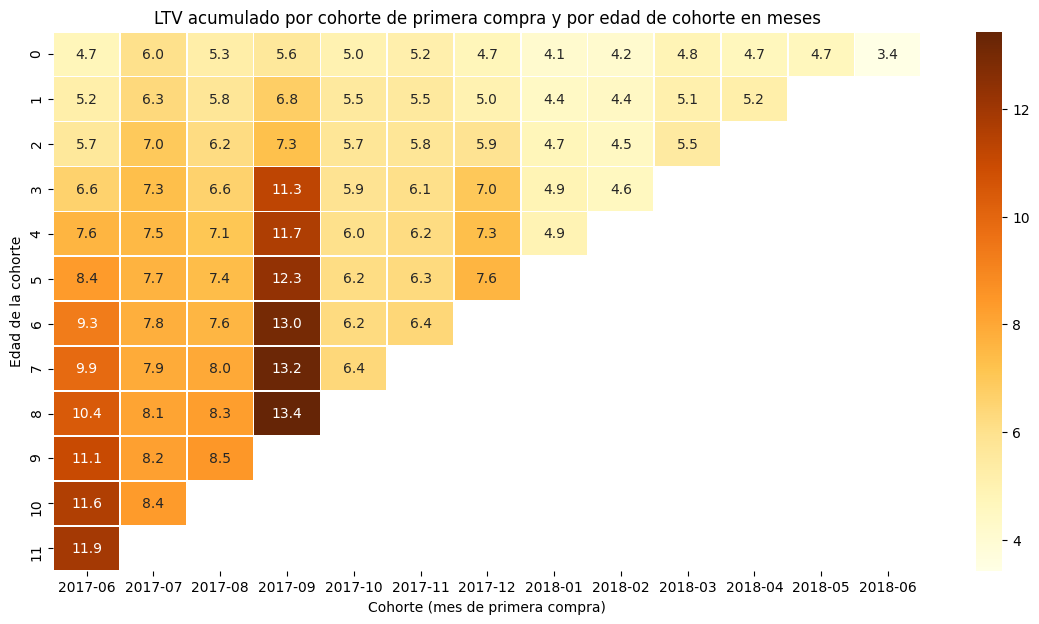

In [54]:
# Le agrego un heatmap para mostrar más claramente el LTV acumulado por cohorte a través de las edades de cohorte.

plt.figure(figsize=(14, 7))
sns.heatmap(ltv_report.astype(float), annot = True, fmt= '.1f', cmap= 'YlOrBr', linewidth = 0.5)
plt.title('LTV acumulado por cohorte de primera compra y por edad de cohorte en meses')
plt.xlabel('Cohorte (mes de primera compra)')
plt.ylabel('Edad de la cohorte')
plt.show()

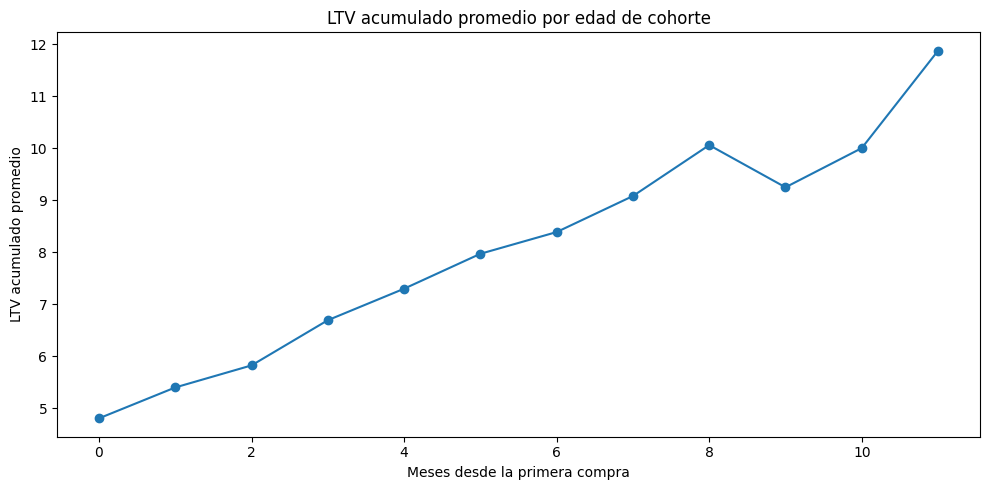

cohort_age
0      4.80
1      5.40
2      5.82
3      6.69
4      7.30
5      7.97
6      8.39
7      9.08
8     10.06
9      9.25
10    10.00
11    11.88
dtype: float64


In [55]:
# Creo una gráfica de línea para visualizar el ltv promedio de todos los cohortes a través del tiempo (desde el mes 0 hast el 11 desde la compra)

avg_ltv_line = ltv_report.mean(axis=1)

plt.figure(figsize = (10,5))
plt.plot(avg_ltv_line.index, avg_ltv_line.values, marker= 'o')
plt.title('LTV acumulado promedio por edad de cohorte')
plt.xlabel('Meses desde la primera compra')
plt.ylabel('LTV acumulado promedio')
plt.tight_layout()
plt.show()

print(avg_ltv_line.round(2))

#### Notas:
- El ltv acumulado crece de manera sostenida mes a mes, hasta el mes 8, luego en el mes 9 baja ligeramente y luego vuelve a subir.
- Los cohortes de junio y septiembre de 2017 muestran un ltv más elevado, lo que puede ser debido a recompra para otros eventos, sin embargo, otras cohortes no muestran ese mismo comportamiento, por lo que es posible que estas dos cohortes sean de personas que son fanáticas de algún tipo de evento en particular.


## Marketing

In [56]:
# Inicio convirtiendo el mes de costo en periodo para poder utilizarlo como un rango.
# Sumo los costos para saber cuánto se ha gastado en total en Marketing.

costs['cost_month'] = costs['dt'].dt.to_period('M')

total_cost = costs['costs'].sum()
print(f'Gasto total de marketing en el periodo: ${total_cost:,.2f}')

Gasto total de marketing en el periodo: $329,131.62


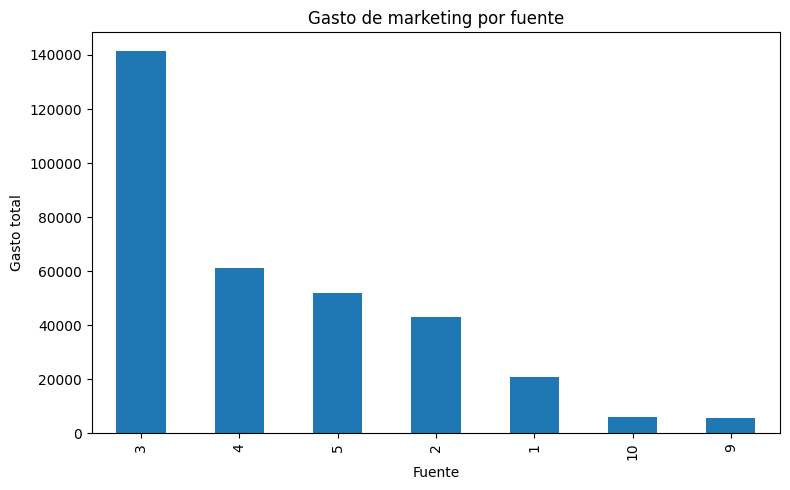

source_id
3     141321.63
4      61073.60
5      51757.10
2      42806.04
1      20833.27
10      5822.49
9       5517.49
Name: costs, dtype: float64


In [57]:
# Calculo el costo de Marketing por fuente de adquisición.

cost_by_source = costs.groupby('source_id')['costs'].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))
cost_by_source.plot(kind='bar')
plt.title('Gasto de marketing por fuente')
plt.xlabel('Fuente')
plt.ylabel('Gasto total')
plt.tight_layout()
plt.show()

print(cost_by_source)

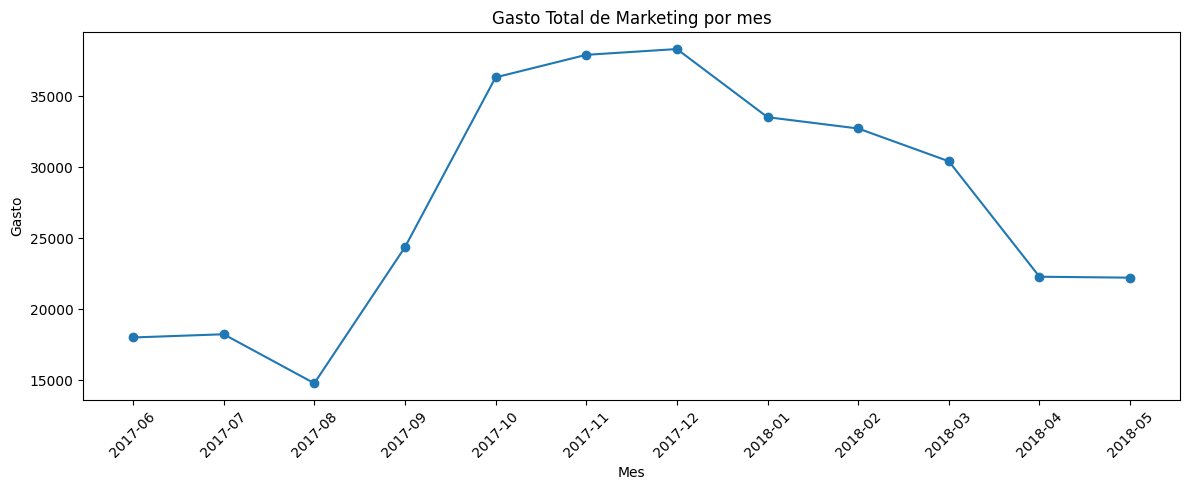

In [58]:
# Agrupo el df de costos por mes.
# Creo una gráfica de línea para visualziar el gasto por mes.

cost_by_month = costs.groupby('cost_month')['costs'].sum()

plt.figure(figsize = (12,5))
plt.plot(cost_by_month.index.astype(str), cost_by_month.values, marker = 'o')
plt.title('Gasto Total de Marketing por mes')
plt.xlabel('Mes')
plt.ylabel('Gasto')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

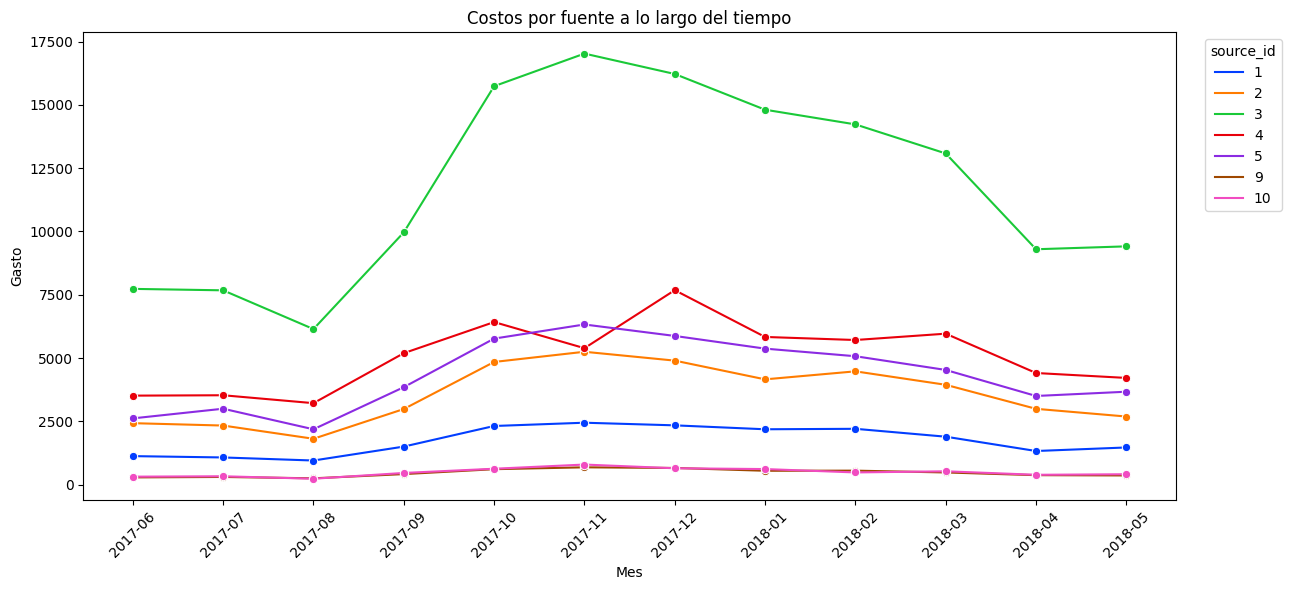

In [59]:
# Ahora muestro costo por mes y por fuente de adquisición.

cost_by_source_by_month = costs.groupby(['cost_month', 'source_id'])['costs'].sum().reset_index()

plt.figure(figsize = (13,6))
sns.lineplot(data = cost_by_source_by_month, 
             x = cost_by_source_by_month['cost_month'].astype(str), 
             y = 'costs',
             hue = 'source_id',
             marker = 'o',
             palette = 'bright'
            )
plt.title('Costos por fuente a lo largo del tiempo')
plt.xlabel('Mes')
plt.ylabel('Gasto')
plt.xticks(rotation = 45)
plt.legend(title = 'source_id', bbox_to_anchor = (1.02, 1), loc = 'upper left')
plt.tight_layout()
plt.show()

#### Notas:
- El gasto en MArketing de la fuente 3 es por mucho, el más alto de todos, todos los meses.

### CAC

In [60]:
# Asigno a cada usuario la fuente de su primera visita y uno esa df con orders para poder tener esa fuente en mi df de orders.

user_source = visits.sort_values('start_ts').groupby('uid')['source_id'].first()
user_source.name = 'source_id'

orders_source = orders.merge(user_source, on='uid', how='left')
orders_source[['uid', 'source_id']].head(5)

,uid,source_id
0,10329302124590727494,1
1,11627257723692907447,2
2,17903680561304213844,2
3,16109239769442553005,2
4,14200605875248379450,3


In [61]:
# Creo cohortes por id de fuente y mes de primera compra para saber por dónde fue que llegaron los usuarios.

buyers_by_source_month = orders_source.drop_duplicates(subset='uid').groupby(
    ['source_id','first_order_month']
)['uid'].nunique().reset_index()
buyers_by_source_month.columns = ['source_id','first_order_month','n_new_buyers']

buyers_by_source_month.head(10)

,source_id,first_order_month,n_new_buyers
0,1,2017-06,190
1,1,2017-07,160
2,1,2017-08,113
3,1,2017-09,227
4,1,2017-10,340
5,1,2017-11,324
6,1,2017-12,331
7,1,2018-01,238
8,1,2018-02,275
9,1,2018-03,281


In [62]:
# Creo un df de costos por fuente y por mes para obtener el gasto total por mes y combinar ese df con buyers_by_source_month y así poder calcular el CAC.

cost_by_source_month_complete = costs.groupby(['source_id', 'cost_month'])['costs'].sum().reset_index()
cost_by_source_month_complete.columns = ['source_id', 'first_order_month', 'monthly_cost']

cac_table = buyers_by_source_month.merge(cost_by_source_month_complete, on=['source_id', 'first_order_month'], how='left')
cac_table['cac'] = cac_table['monthly_cost'] / cac_table['n_new_buyers']

cac_table.head(10)

,source_id,first_order_month,n_new_buyers,monthly_cost,cac
0,1,2017-06,190,1125.61,5.924263
1,1,2017-07,160,1072.88,6.705500
2,1,2017-08,113,951.81,8.423097
3,1,2017-09,227,1502.01,6.616784
4,1,2017-10,340,2315.75,6.811029
5,1,2017-11,324,2445.16,7.546790
6,1,2017-12,331,2341.20,7.073112
7,1,2018-01,238,2186.18,9.185630
8,1,2018-02,275,2204.48,8.016291
9,1,2018-03,281,1893.09,6.736975


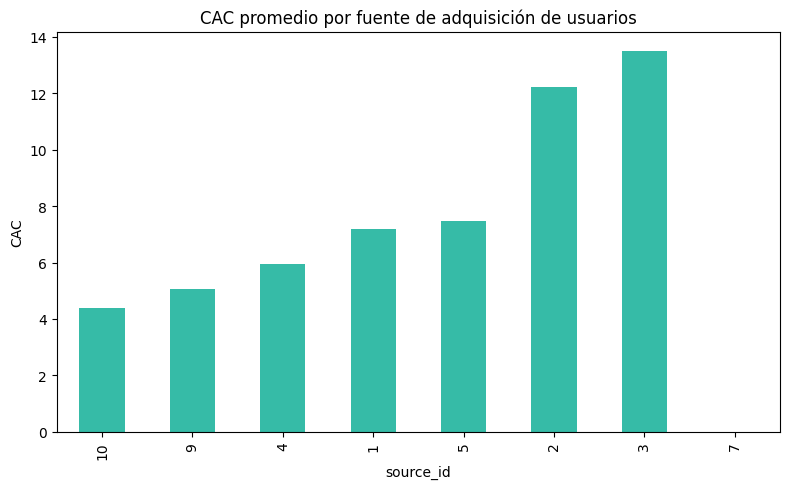

source_id
10     4.38
9      5.07
4      5.93
1      7.19
5      7.47
2     12.21
3     13.49
7       NaN
Name: cac, dtype: float64

In [63]:
# Creo una bar chart para mostrar el CAC promedio por fuente de adquisición.

cac_by_source = (
    cost_by_source_month_complete.groupby('source_id')['monthly_cost'].sum() /
    buyers_by_source_month.groupby('source_id')['n_new_buyers'].sum()
).sort_values()
cac_by_source.name = 'cac'

plt.figure(figsize = (8,5))
cac_by_source.plot(kind='bar', color= '#36BBA7')
plt.title('CAC promedio por fuente de adquisición de usuarios')
plt.xlabel('source_id')
plt.ylabel('CAC')
plt.tight_layout()
plt.show()

cac_by_source.round(2)

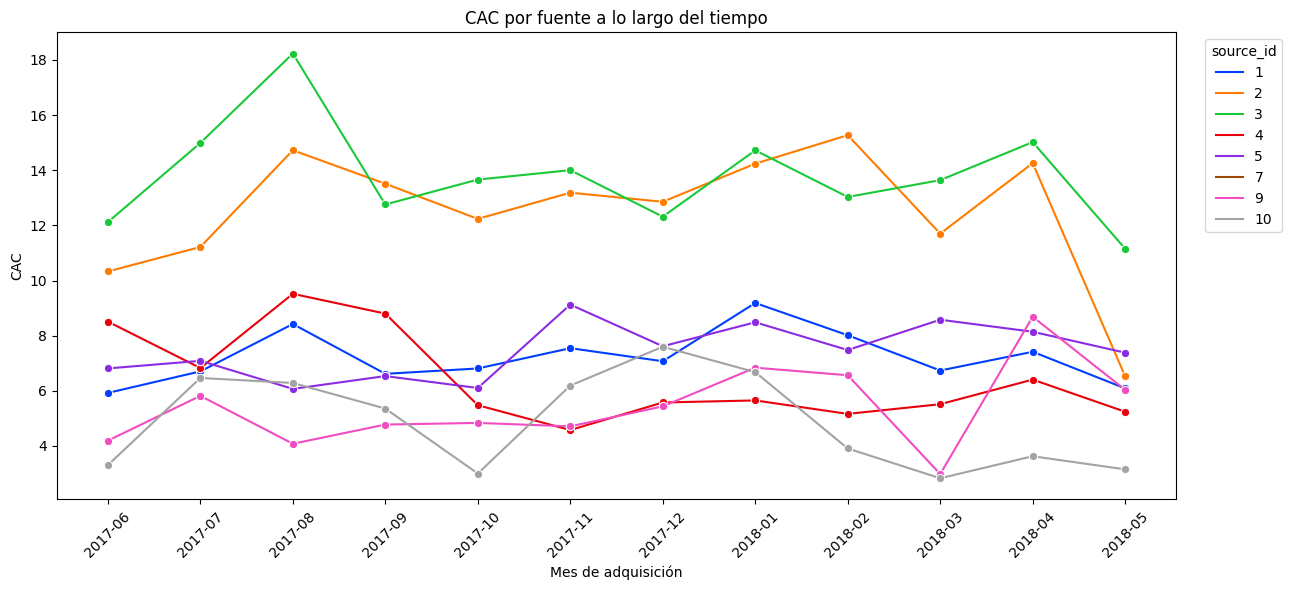

In [64]:
# Creo una grafica de líneas para mostrar el CAC por fuente mes a mes.

plt.figure(figsize = (13,6))
sns.lineplot(
    data=cac_table, 
    x=cac_table['first_order_month'].astype(str), 
    y='cac', 
    hue='source_id', 
    marker='o', 
    palette='bright'
)
plt.title('CAC por fuente a lo largo del tiempo')
plt.xlabel('Mes de adquisición')
plt.ylabel('CAC')
plt.xticks(rotation=45)
plt.legend(title='source_id', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

#### Notas:
- La fuente 3 es claramente la fuente con mayor costo de adquisición de clientes. Solo en 3 meses ha sido superada por la fuente 4, pero en los demás meses se mantiene como la fuente con mayor CAC.

### ROMI

In [65]:
# Inicio calculando el LTV acumulado por fuente y edad de cohorte para compararlo contra el cAC y así obtener el ROMI.

ltv_by_source = orders_source.groupby(['source_id', 'first_order_month', 'cohort_age']).agg({'revenue':'sum'}).reset_index()
ltv_by_source = ltv_by_source.sort_values(['source_id', 'first_order_month', 'cohort_age'])
ltv_by_source['cumulative_revenue'] = ltv_by_source.groupby(['source_id', 'first_order_month'])['revenue'].cumsum()

ltv_by_source = ltv_by_source.merge(buyers_by_source_month, on=['source_id', 'first_order_month'])
ltv_by_source['ltv'] = ltv_by_source['cumulative_revenue'] / ltv_by_source['n_new_buyers']

ltv_by_source.head(10)


,source_id,first_order_month,cohort_age,revenue,cumulative_revenue,n_new_buyers,ltv
0,1,2017-06,0,1378.70,1378.70,190,7.256316
1,1,2017-06,1,414.98,1793.68,190,9.440421
2,1,2017-06,2,419.43,2213.11,190,11.647947
3,1,2017-06,3,714.24,2927.35,190,15.407105
4,1,2017-06,4,811.20,3738.55,190,19.676579
5,1,2017-06,5,389.34,4127.89,190,21.725737
6,1,2017-06,6,490.48,4618.37,190,24.307211
7,1,2017-06,7,479.23,5097.60,190,26.829474
8,1,2017-06,8,432.15,5529.75,190,29.103947
9,1,2017-06,9,316.30,5846.05,190,30.768684


In [66]:
# Combino la tabla de ROMI y la de LTV por fuente para agregar el CAC y calcular el ROMI.

romi_table = ltv_by_source.merge(
    cac_table[['source_id', 'first_order_month', 'cac']], on= ['source_id', 'first_order_month']
)
romi_table['romi'] = romi_table['ltv'] / romi_table['cac']

romi_table.head(10)

,source_id,first_order_month,cohort_age,revenue,cumulative_revenue,n_new_buyers,ltv,cac,romi
0,1,2017-06,0,1378.70,1378.70,190,7.256316,5.924263,1.224847
1,1,2017-06,1,414.98,1793.68,190,9.440421,5.924263,1.593518
2,1,2017-06,2,419.43,2213.11,190,11.647947,5.924263,1.966143
3,1,2017-06,3,714.24,2927.35,190,15.407105,5.924263,2.600679
4,1,2017-06,4,811.20,3738.55,190,19.676579,5.924263,3.321355
5,1,2017-06,5,389.34,4127.89,190,21.725737,5.924263,3.667247
6,1,2017-06,6,490.48,4618.37,190,24.307211,5.924263,4.102993
7,1,2017-06,7,479.23,5097.60,190,26.829474,5.924263,4.528744
8,1,2017-06,8,432.15,5529.75,190,29.103947,5.924263,4.912670
9,1,2017-06,9,316.30,5846.05,190,30.768684,5.924263,5.193673


In [ ]:
# Creo una pivot con la información de edad de cohorte y fuente de adquisicón para poder sacar el romi por edad y por fuente.

romi_by_source_age = romi_table.pivot_table(
    index = 'cohort_age',
    columns = 'source_id',
    values = 'romi',
    aggfunc = 'mean'
)

# Creo una gráfica de líneas para mostrar el ROMI a través de la edad de las cohortes por fuente de adquisición 
# y así poder ver visualmente cuándo es que la fuente recupera la inversión (cruza 1).

plt.figure(figsize = (12,6))
for src in romi_by_source_age.columns:
    plt.plot(romi_by_source_age.index, romi_by_source_age[src], marker='o', label=f'source {src}')
plt.axhline(1, color='black', linestyle='--', linewidth=1, label= 'Punto de equilibrio (ROMI=1)')
plt.title('ROMI promedio por fuente a lo largo de la edad de la cohorte')
plt.xlabel('Meses desde la primera compra')
plt.ylabel('ROMI')
plt.legend(bbox_to_anchor=(1.02,1), loc='upper left')
plt.tight_layout()
plt.show()

romi_by_source_age.round(2)

In [ ]:
# Calculo cuál es la edad de cada cohorte en la que el ROMI promedio alcanza (o supera) el punto de equilibrio.

payback_romi = {}
for src in romi_by_source_age. columns:
    serie = romi_by_source_age[src].dropna()
    recovered = serie[serie >= 1]
    payback_romi[src] = recovered.index.min() if not recovered.empty else float('nan')

payback_romi = pd.Series(payback_romi, name='meses_para_recuperar_inversión').sort_values()
payback_romi

### Dispositivos por fuente de adquisición

In [ ]:
# Creo un df para agrupar las visitas por fecha y por dispositivo, contando los uids unicos para ver la cantidad
# de visitantes por día y dispositivo.

dau_by_device = visits.groupby(['visit_date', 'device'])['uid'].nunique().reset_index()

# Creo una grafica de linea para ver el flujo de visitantes por dispositivo.

plt.figure(figsize=(13, 5))
sns.lineplot(data=dau_by_device, x='visit_date', y='uid', hue='device')
plt.title('Usuarios únicos por día y por dispositivo')
plt.xlabel('Fecha')
plt.ylabel('Usuarios únicos')
plt.tight_layout()
plt.show()

In [ ]:
# Agrupo visits para obtener la duración de las sesiones promedio por dispositivo.

sessions_duration_by_device = visits.groupby('device')['session_duration_sec'].mean()

plt.figure(figsize=(6,5))
sessions_duration_by_device.plot(kind='bar', color=['#615FFF', '#FFD230'])
plt.title('Duración promedio de sesiones por dispositivo')
plt.ylabel('Segundos')
plt.tight_layout()
plt.show()

sessions_duration_by_device.round(1)

In [ ]:
# Calculo la cantidad de ordenes y los ingresos por dispositivo.

user_device = visits.sort_values('start_ts').groupby('uid')['device'].first()
orders_source['device'] = orders_source['uid'].map(user_device)

orders_by_device = orders_source.groupby('device')['uid'].count()
revenue_by_device = orders_source.groupby('device')['revenue'].sum()

fig, axes = plt.subplots(1, 2, figsize=(11,5))
orders_by_device.plot(kind='bar', ax=axes[0], color=['#615FFF', '#FFD230'])
axes[0].set_title('Pedidos por dispositivo')
revenue_by_device.plot(kind='bar', ax=axes[1], color=['#615FFF', '#FFD230'])
axes[1].set_title('Ingreso total por dispositivo')

plt.tight_layout()
plt.show()

In [ ]:
# Creo una tabla comparativa de CAC. LTV y ROMI por fuente de adquisición.

ltv_total_by_source = (
    orders_source.groupby('source_id')['revenue'].sum() /
    orders_source.drop_duplicates('uid').groupby('source_id')['uid'].count()
)

romi_total_by_source = ltv_total_by_source / cac_by_source

comparison = pd.DataFrame({
    'CAC' : cac_by_source,
    'LTV': ltv_total_by_source,
    'ROMI': romi_total_by_source
}).round(2)

comparison

In [ ]:
# Creo una grafica de columnas para mostra el CAC y LTV promedio de cada fuente.

fig, ax = plt.subplots(figsize=(9, 5))
comparison[['CAC', 'LTV']].plot(kind='bar', ax=ax, color=['#FF2056', '#05DF72'])
plt.title('CAC vs LTV por fuent de adquisición')
plt.ylabel('$ por usuario')
plt.tight_layout()
plt.show()

### Notas:
- Las fuentes de adquisición 3, 4 y 10 tienen un CAC más alto que el LTV de los clientes que llegan por ellas.
- La fuente 7 es interesante porque no muestra inversión realizada pero sí ha generado ingresos, por lo que valdría la pena explorar si se trata de falta de datos o si efectivamente es un canal que puede ser explotado mejor para incrementar los ingresos que llegan por ahi.

## Conclusiones Generales
- El uso de la app y las compras parece responder a eventos sin recurrencia: en octubre y diciembre 2017 hubo picos, posiblemente debidos a interés de las personas en eventos realizados en esas fechas.
- Los usuarios activos en un mes no vuelven seguido, normalmente no vuelven a hacerlo durante el mismo mes.
- La gran mayoría de los usuarios que compran lo hacen en el día en el que realizan su primera visita, posiblemente debido a haber planeado adquirir boletos de un evento en particular.
- El LTV crece de manera sostenida a través de la edad de los cohortes de compra, impulsado principalmente por la primera compra.
- EL gasto en Marketing muestra mucha variación entre el ROMI entre las diferentes fuentes, sinedo la fuente 3 una de las que recibe mayor inversión pero sin lograr recuperala (ROMI: 0.39).

## Sugerencias
- Reasignar parte del presupuesto de la fuente 3 a la fuente 1: la fuente 3 no solo no es redituable (ROMI de 0.39; la de menor ROMI), sino que también es la fuente en la que se invierte más (). Incluso en las edades más altas de cohorts no logra llegar a 0.5 de ROMI).
- Mantener el gasto de las fuentes 2, 5 y 9: alcanzan el punto de equilibro entre los meses 3 y 4.
- Reducir el gasto de inversión en las fuentes 4 y 10: la 10 no recupera la inversión, mientras que la 4 se demora hasta el mes 10.
- Explorar la diferencia entre la conversión de touch y desktop.